# Random Geometric Graphs: What Mid-Band Eigenvectors Are, and What Clustering on Them Means

**The task.** Scatter 1000 points uniformly in the unit square, join every pair closer than
$r=0.1$, give each edge a weight proportional to the distance it spans, take the Laplacian
spectrum, look at eigenvectors 10, 15 and 20, and build clusters from those three.

**The question that makes it a lesson.** Each of those steps has a defensible alternative, and the
last one is not standard practice: textbook spectral clustering uses the *bottom* of the spectrum,
not modes 10, 15 and 20. So this notebook does what was asked, and then measures what it got:

1. What does a weight *proportional to distance* mean, given that a Laplacian weight is a coupling
   strength while distance is a cost? (Section 2)
2. What do modes 10, 15 and 20 actually look like on a uniform point cloud, and is there anything
   to predict them against? (Sections 5 and 6)
3. Do clusters built from those three modes beat the obvious non-spectral alternative -- k-means on
   the raw $(x,y)$ coordinates -- at anything measurable? (Section 7)

**This data is synthetic and illustrative, not measured.** That is deliberate, and it buys
something a real dataset cannot: a uniform point cloud with a radius cutoff has a known continuum
limit, so the eigenvalues and eigenvectors can be checked against an analytic formula rather than
against a plot that merely looks plausible. Every number below is computed from the sample; the
analytic predictions are labelled as predictions.

**Prerequisites.** The combinatorial Laplacian $L=D-W$, its eigendecomposition
$L=U\Lambda U^\top$, and the reading of $\lambda_k=u_k^\top Lu_k$ as a graph frequency
(Lesson 1). No measured graph signal appears anywhere; in Section 7 the vectors being clustered are
the eigenvectors themselves.

**Conventions used throughout.**

- $n=1000$ nodes indexed $0,\dots,999$ in sampling order; that order is fixed and never permuted.
- Symmetric nonnegative weights, no self-loops: $W_{ij}=W_{ji}\ge 0$, $W_{ii}=0$.
- $D_{ii}=\sum_j W_{ij}$ (the *weighted* degree), $L=D-W$, eigenvalues ordered
  $0=\lambda_1\le\lambda_2\le\cdots\le\lambda_n$.
- **Eigenvector numbering is 1-based**, matching that ordering: "the 10th eigenvector" is $u_{10}$,
  the one paired with $\lambda_{10}$, which is `U[:, 9]` in NumPy. $u_1$ is the constant vector.
  This matters -- a 0-based reading would shift every picture in Section 6 by one mode.
- Coordinates are dimensionless numbers in $[0,1]$. Edge weights under the requested definition
  therefore carry units of length, and Dirichlet energies carry length x (signal units)$^2$.

In [1]:
import numpy as np
import scipy
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.spatial import cKDTree
import sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

SEED = 11
rng = np.random.default_rng(SEED)

# Plot conventions carried over from the earlier lessons.
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.constrained_layout.use": True,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
})
C_LINE, C_RED, C_GREEN, C_ORANGE = "#2b6cb0", "#c53030", "#2f855a", "#e07a3f"

for name, mod in [("numpy", np), ("scipy", scipy), ("networkx", nx),
                  ("matplotlib", matplotlib), ("scikit-learn", sklearn)]:
    print(f"{name:14s} {mod.__version__}")
print(f"seed           {SEED}")

numpy          2.5.3
scipy          1.18.1
networkx       3.6.1
matplotlib     3.11.1
scikit-learn   1.9.1
seed           11


---
## 1. From points to a graph: the mapping, stated before any code

Nothing here is observed, so the generative model *is* the specification. It is still worth writing
out exactly what plays each role, because that table is the thing a reader has to trust:

| Graph object | Definition in this notebook |
|---|---|
| node $i$ | one sampled point, $i=0,\dots,999$ |
| coordinates $p_i=(x_i,y_i)$ | drawn i.i.d. uniform on $[0,1]^2$ |
| edge $\{i,j\}$ | present iff $d_{ij}=\lVert p_i-p_j\rVert_2 < r$, with $r=0.1$ |
| weight $W_{ij}$ | proportional to $d_{ij}$ (Section 2 examines this choice) |
| graph signal | none |

This object is a **random geometric graph** $G(n,r)$ (Penrose, *Random Geometric Graphs*, OUP 2003).
Two of its properties are worth predicting *before* measuring them, because a prediction that
survives contact with the sample is evidence the construction did what was intended:

- **Mean degree.** A point far from the boundary has $n\pi r^2$ neighbours in expectation, here
  $1000\pi(0.1)^2\approx 31.4$. Points near the edge of the square see a truncated disc, so the
  measured mean will come in *below* that. The gap is the boundary effect, and it is not a defect --
  it is the reason the continuum modes in Section 5 are Neumann (reflecting) rather than periodic.
- **Connectivity.** $G(n,r)$ becomes connected, with high probability, once
  $r\gtrsim\sqrt{\log n/(\pi n)}$, here $\approx 0.047$. At $r=0.1$ we sit comfortably above that,
  so one connected component is expected -- but expected is not the same as true for *this* sample,
  so the code checks it, and the check is load-bearing: the multiplicity of $\lambda=0$ is the
  component count, and a second component would change what every later eigenvector means.

In [2]:
N = 1000          # nodes
R = 0.10          # connection radius, same units as the coordinates

coords = rng.random((N, 2))                       # (N,2) array of (x,y) in [0,1]^2

# Radius search. query_pairs returns each unordered pair once, so `pairs` is an (m,2)
# array with i<j -- the edge list, in a fixed order reused everywhere below.
tree = cKDTree(coords)
pairs = np.array(sorted(tree.query_pairs(r=R)), dtype=int)
dist = np.linalg.norm(coords[pairs[:, 0]] - coords[pairs[:, 1]], axis=1)
n_edges = len(pairs)

print(f"nodes                                  : {N}")
print(f"edges                                  : {n_edges}")
print(f"mean degree, measured                  : {2*n_edges/N:.2f}")
print(f"mean degree, bulk prediction N*pi*R^2  : {N*np.pi*R**2:.2f}   (boundary lowers the measured value)")
print(f"edge length  min / mean / max          : {dist.min():.4f} / {dist.mean():.4f} / {dist.max():.4f}   (cutoff {R})")
print(f"edge length mean, prediction 2R/3      : {2*R/3:.4f}   (uniform density inside the disc)")
print(f"connectivity threshold sqrt(log n/pi n): {np.sqrt(np.log(N)/(np.pi*N)):.4f}")

nodes                                  : 1000
edges                                  : 14531
mean degree, measured                  : 29.06
mean degree, bulk prediction N*pi*R^2  : 31.42   (boundary lowers the measured value)
edge length  min / mean / max          : 0.0003 / 0.0658 / 0.1000   (cutoff 0.1)
edge length mean, prediction 2R/3      : 0.0667   (uniform density inside the disc)
connectivity threshold sqrt(log n/pi n): 0.0469


---
## 2. The weight definition, taken literally and then interrogated

The specification says *weight proportional to distance*:

$$W_{ij}=\alpha\,d_{ij}\quad\text{for }d_{ij}<r,\qquad W_{ij}=0\text{ otherwise.}$$

Two remarks before we use it.

**The constant $\alpha$ is irrelevant to everything except the eigenvalue scale.** $L$ is linear in
$W$, so replacing $W$ by $\alpha W$ replaces $L$ by $\alpha L$: every eigenvector is unchanged and
every eigenvalue is multiplied by $\alpha$. We therefore set $\alpha=1$ and write $W_{ij}=d_{ij}$.
Any claim below about eigenvector shape or about clusters is automatically independent of $\alpha$;
any claim about a raw eigenvalue is not, which is one reason Section 4 never reports an eigenvalue
without a yardstick beside it.

**A Laplacian weight is a coupling, and distance is a cost.** Since
$x^\top Lx=\sum_{\{i,j\}\in E}W_{ij}(x_i-x_j)^2$ penalises disagreement *in proportion to the
weight*, a large $W_{ij}$ asserts that $i$ and $j$ ought to agree strongly. Setting $W_{ij}=d_{ij}$
therefore says: **the further apart two connected points are, the more tightly they are coupled**,
and two points nearly on top of each other are nearly uncoupled. As a model of spatial similarity
that is backwards. The usual repair is an affinity that *decreases* with distance, for example the
cone kernel

$$W^{\mathrm{aff}}_{ij}=1-\frac{d_{ij}}{r},$$

chosen here over the more common Gaussian $\exp(-d_{ij}^2/2\sigma^2)$ only because it needs no
bandwidth parameter and vanishes continuously at the cutoff -- nothing to tune, no discontinuity to
explain.

We keep the requested definition as the primary object of study and carry the affinity alongside as
a control, so that "does the cost/affinity distinction matter here?" becomes a measurement rather
than a warning. Section 4 answers it, and the answer is more interesting than *it breaks
everything*.

In [3]:
w_cost = dist.copy()          # W_ij = d_ij          <- the requested definition (alpha = 1)
w_aff = 1.0 - dist / R        # W_ij = 1 - d_ij/r    <- distance-decaying control
w_unw = np.ones_like(dist)    # W_ij = 1             <- topology only, used for the null model


def dense_W(vals):
    W = np.zeros((N, N))
    W[pairs[:, 0], pairs[:, 1]] = vals
    W[pairs[:, 1], pairs[:, 0]] = vals
    return W


W_cost, W_aff, W_unw = dense_W(w_cost), dense_W(w_aff), dense_W(w_unw)

G = nx.Graph()
G.add_nodes_from(range(N))
G.add_weighted_edges_from(
    [(int(i), int(j), float(w)) for (i, j), w in zip(pairs, w_cost)]
)

# --- invariants, checked rather than assumed -------------------------------------
for name, W in [("cost", W_cost), ("affinity", W_aff), ("unweighted", W_unw)]:
    assert np.array_equal(W, W.T), f"{name}: not symmetric"
    assert np.all(np.diag(W) == 0), f"{name}: self-loops present"
    assert np.all(W >= 0), f"{name}: negative weight"
    deg = W.sum(1)
    print(f"{name:11s} weighted degree   min {deg.min():.4f}   mean {deg.mean():.4f}   max {deg.max():.4f}")

print()
print(f"connected                              : {nx.is_connected(G)}")
print(f"connected components                   : {nx.number_connected_components(G)}")
print(f"isolated nodes (degree 0)              : {sum(1 for _, d in G.degree() if d == 0)}")
print(f"unweighted degree  min / max           : {min(d for _, d in G.degree())} / {max(d for _, d in G.degree())}")

cost        weighted degree   min 0.5691   mean 1.9131   max 3.1552
affinity    weighted degree   min 2.3317   mean 9.9306   max 15.8303
unweighted  weighted degree   min 9.0000   mean 29.0620   max 42.0000

connected                              : True
connected components                   : 1
isolated nodes (degree 0)              : 0
unweighted degree  min / max           : 9 / 42


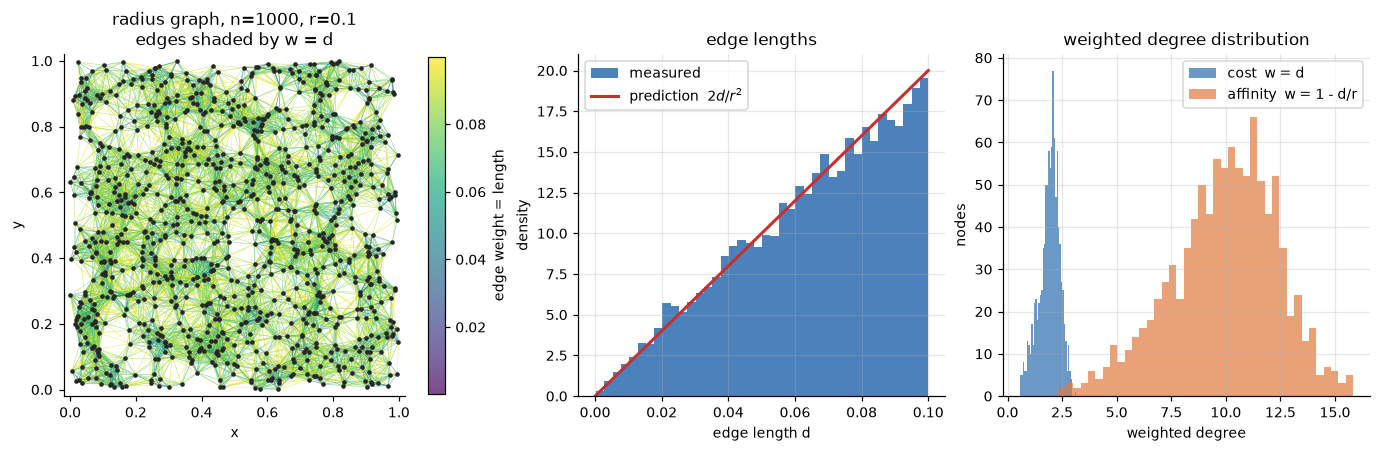

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.0))

# (a) the graph itself, edges shaded by the requested weight w = d
ax = axes[0]
segs = coords[pairs]                                  # (m, 2, 2)
lc = LineCollection(segs, array=w_cost, cmap="viridis", linewidths=0.35, alpha=0.7)
ax.add_collection(lc)
ax.scatter(coords[:, 0], coords[:, 1], s=4, color="0.15", zorder=3)
ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02), aspect="equal",
       title=f"radius graph, n={N}, r={R}\nedges shaded by w = d", xlabel="x", ylabel="y")
ax.grid(False)
fig.colorbar(lc, ax=ax, fraction=0.046, label="edge weight = length")

# (b) edge-length distribution. Uniform density gives P(d < s | d < r) = (s/r)^2,
#     so the density is proportional to d and long edges dominate by count.
ax = axes[1]
ax.hist(dist, bins=40, color=C_LINE, alpha=0.85, density=True, label="measured")
s = np.linspace(0, R, 200)
ax.plot(s, 2 * s / R**2, color=C_RED, lw=2, label=r"prediction  $2d/r^2$")
ax.set(xlabel="edge length d", ylabel="density", title="edge lengths")
ax.legend()

# (c) what the two weight definitions do to the degree distribution
ax = axes[2]
ax.hist(W_cost.sum(1), bins=40, color=C_LINE, alpha=0.7, label="cost  w = d")
ax.hist(W_aff.sum(1), bins=40, color=C_ORANGE, alpha=0.7, label="affinity  w = 1 - d/r")
ax.set(xlabel="weighted degree", ylabel="nodes", title="weighted degree distribution")
ax.legend()
plt.show()

The edge-length histogram is worth pausing on, because it explains why the two weightings will
differ less than the discussion above implies. Under a uniform point density the number of
neighbours within distance $s$ grows like $s^2$, so edge lengths have density $2d/r^2$ on $[0,r]$:
**most edges are long**. The near-coincident pairs that $w=d$ treats as uncoupled do exist, but
they are rare, and they sit at the bottom of the weight range where they contribute least to $L$.
The backwards-coupling objection is real in principle; its magnitude is an empirical question, and
Section 4 measures it.

---
## 3. The Laplacian and its eigendecomposition

With $W$ fixed, everything else follows mechanically:

$$D_{ii}=\sum_j W_{ij},\qquad L=D-W,\qquad L=U\Lambda U^\top,\qquad
\lambda_k=u_k^\top Lu_k=\sum_{\{i,j\}\in E}W_{ij}(u_{k,i}-u_{k,j})^2 .$$

The last equality is why $\lambda_k$ is called a graph frequency: it is the Dirichlet energy of a
unit-norm vector -- how much that pattern disagrees across edges, weighted. (The edge sum carries
no $\tfrac12$; the equivalent ordered-pair sum $\tfrac12\sum_{ij}W_{ij}(x_i-x_j)^2$ does. This
notebook uses the edge form, and the check at the end of Section 6 computes it both ways.)

$n=1000$ is small enough for an exact dense symmetric solve, so we use `numpy.linalg.eigh` -- which
assumes symmetry and returns an orthonormal $U$ with ascending $\lambda$ -- rather than a sparse
iterative solver. Four invariants get checked, because a silent failure in any of them would
invalidate every plot that follows:

1. $L$ symmetric and $L\mathbf{1}=0$ (rows sum to zero, by construction of $D$);
2. $\lambda_1\approx 0$, and the number of numerically-zero eigenvalues equals the component count;
3. eigenpair residual $\lVert LU-U\Lambda\rVert_{\max}$ at machine precision;
4. $U^\top U=I$, which is what licenses every projection argument below.

In [5]:
def laplacian_spectrum(W, label):
    deg = W.sum(1)
    L = np.diag(deg) - W
    lam, U = np.linalg.eigh(L)                 # ascending eigenvalues, orthonormal columns

    n_zero = int(np.sum(np.abs(lam) < 1e-8 * max(1.0, lam[-1])))
    resid = np.abs(L @ U - U * lam).max()
    orth = np.abs(U.T @ U - np.eye(len(lam))).max()
    rq = float(U[:, 14] @ L @ U[:, 14])        # Rayleigh quotient of u_15, should equal lambda_15

    print(f"--- {label} ---")
    print(f"  symmetry  max|L - L^T|             : {np.abs(L - L.T).max():.2e}")
    print(f"  row sums  max|L 1|                 : {np.abs(L.sum(1)).max():.2e}")
    print(f"  lambda_1                           : {lam[0]:+.3e}   (exact value is 0)")
    print(f"  numerically zero eigenvalues       : {n_zero}   (= number of components)")
    print(f"  residual  max|LU - U diag(lambda)| : {resid:.2e}")
    print(f"  orthonormality max|U^T U - I|      : {orth:.2e}")
    print(f"  u_15^T L u_15 vs lambda_15         : {rq:.6f} vs {lam[14]:.6f}")
    print(f"  lambda_2 / lambda_n                : {lam[1]:.4f} / {lam[-1]:.4f}")
    return deg, L, lam, U


deg_cost, L_cost, lam_cost, U_cost = laplacian_spectrum(W_cost, "cost weights  w = d")
print()
deg_aff, L_aff, lam_aff, U_aff = laplacian_spectrum(W_aff, "affinity weights  w = 1 - d/r")
print()
deg_unw, L_unw, lam_unw, U_unw = laplacian_spectrum(W_unw, "unweighted  w = 1")

--- cost weights  w = d ---
  symmetry  max|L - L^T|             : 0.00e+00
  row sums  max|L 1|                 : 8.88e-16
  lambda_1                           : -3.357e-16   (exact value is 0)
  numerically zero eigenvalues       : 1   (= number of components)
  residual  max|LU - U diag(lambda)| : 2.51e-15
  orthonormality max|U^T U - I|      : 3.55e-15
  u_15^T L u_15 vs lambda_15         : 0.307115 vs 0.307115
  lambda_2 / lambda_n                : 0.0271 / 3.3621

--- affinity weights  w = 1 - d/r ---
  symmetry  max|L - L^T|             : 0.00e+00
  row sums  max|L 1|                 : 4.44e-15
  lambda_1                           : -1.681e-15   (exact value is 0)
  numerically zero eigenvalues       : 1   (= number of components)
  residual  max|LU - U diag(lambda)| : 4.23e-14
  orthonormality max|U^T U - I|      : 5.20e-15
  u_15^T L u_15 vs lambda_15         : 0.759881 vs 0.759881
  lambda_2 / lambda_n                : 0.0649 / 16.6637



--- unweighted  w = 1 ---
  symmetry  max|L - L^T|             : 0.00e+00
  row sums  max|L 1|                 : 0.00e+00
  lambda_1                           : +6.283e-15   (exact value is 0)
  numerically zero eigenvalues       : 1   (= number of components)
  residual  max|LU - U diag(lambda)| : 1.15e-13
  orthonormality max|U^T U - I|      : 3.55e-15
  u_15^T L u_15 vs lambda_15         : 3.909070 vs 3.909070
  lambda_2 / lambda_n                : 0.3404 / 45.1519


---
## 4. Reading the spectrum against yardsticks

A bare eigenvalue is not a finding. Whatever $\lambda_2$ turns out to be, the only useful question
is *small compared to what?* Three references are available here, and they answer different
questions.

**(a) An analytic upper bound.** For any connected graph on $n$ nodes,
$\lambda_2\le\frac{n}{n-1}d_{\min}$ (Fiedler 1973): algebraic connectivity cannot exceed the
weighted degree of the worst-connected node. If $\lambda_2$ sits near that bound, the graph is as
well connected as its weakest node permits and there is no bottleneck to find -- the small
$\lambda_2$ is just a report on one node. If $\lambda_2$ falls far *below* the bound, something
global is holding it down.

**(b) A degree-preserving rewiring null.** Randomly rewiring edges while holding every degree fixed
destroys the geometry and keeps the degree sequence, so comparing against it asks: *is this value
explained by the degree distribution, or by the spatial embedding?* We run the null on the
**unweighted** graph, because a rewired edge joins points at an arbitrary distance and a "length"
weight attached to it would be a number with no referent.

**(c) The continuum limit.** This is the yardstick a real dataset almost never offers. As
$n\to\infty$ with $r$ shrinking slowly, the graph Laplacian of a uniform sample converges, up to
scale, to the negative continuum Laplacian $-\Delta$ on the square with **Neumann** boundary
conditions -- Neumann because a boundary point simply has fewer neighbours, with nothing forcing
its value to zero (Belkin and Niyogi 2008). Expanding $(Lx)_i=\sum_j W_{ij}(x_i-x_j)$ to second
order gives

$$(Lx)_i \;\approx\; -\frac{n}{2}\Big(\textstyle\int_{\lVert z\rVert<r} w(\lVert z\rVert)\,z_1^2\,dz\Big)\,\Delta x(p_i)
\;=\; -c_w\,\Delta x(p_i),$$

so the graph eigenvalues should track $c_w\,\pi^2(a^2+b^2)$ -- the eigenvalues of $-\Delta$ under
Neumann conditions, whose eigenfunctions are $\cos(a\pi x)\cos(b\pi y)$ for integers $a,b\ge 0$.
Evaluating the integral for each weighting:

$$c_{\text{unweighted}}=\frac{n\pi r^4}{8},\qquad
c_{\text{cost}}=\frac{n\pi r^5}{10},\qquad
c_{\text{affinity}}=\frac{n\pi r^4}{40}.$$

Note what that says about Section 2's worry. **All three weightings have the same continuum limit
up to a constant factor**, because all three kernels are isotropic functions of distance supported
in a small ball; only the constant differs. That gives a sharp, parameter-free prediction:
$\lambda_k^{\text{cost}}/\lambda_k^{\text{aff}}\to 4r=0.4$. Cost-versus-affinity is a serious
modelling error in general -- on a graph whose edge costs span orders of magnitude it inverts the
geometry -- but a *radius* graph has already confined every edge to one small length scale, which
is what defuses it here.

In [6]:
# (a) Fiedler's bound, per weighting
print("lambda_2 against the bound  lambda_2 <= n/(n-1) * d_min")
for label, lam, deg in [("cost", lam_cost, deg_cost), ("affinity", lam_aff, deg_aff),
                        ("unweighted", lam_unw, deg_unw)]:
    bound = N / (N - 1) * deg.min()
    print(f"  {label:11s} lambda_2 = {lam[1]:.5f}   bound = {bound:.5f}   "
          f"ratio = {lam[1]/bound:.3f}")

# (b) degree-preserving rewiring null, on the unweighted topology
N_NULL = 20
null_lam2 = np.empty(N_NULL)
for t in range(N_NULL):
    H = nx.double_edge_swap(G.copy(), nswap=10 * n_edges, max_tries=200 * n_edges, seed=SEED + t)
    A = nx.to_numpy_array(H, nodelist=range(N), weight=None)     # topology only
    null_lam2[t] = np.linalg.eigvalsh(np.diag(A.sum(1)) - A)[1]

print()
print(f"unweighted lambda_2, geometric graph    : {lam_unw[1]:.4f}")
print(f"unweighted lambda_2, rewired null       : {null_lam2.mean():.4f} +/- {null_lam2.std():.4f} "
      f"over {N_NULL} rewirings")
print(f"ratio null / geometric                  : {null_lam2.mean()/lam_unw[1]:.1f}x")

lambda_2 against the bound  lambda_2 <= n/(n-1) * d_min
  cost        lambda_2 = 0.02706   bound = 0.56967   ratio = 0.048
  affinity    lambda_2 = 0.06488   bound = 2.33401   ratio = 0.028
  unweighted  lambda_2 = 0.34045   bound = 9.00901   ratio = 0.038



unweighted lambda_2, geometric graph    : 0.3404
unweighted lambda_2, rewired null       : 8.5265 +/- 0.0621 over 20 rewirings
ratio null / geometric                  : 25.0x


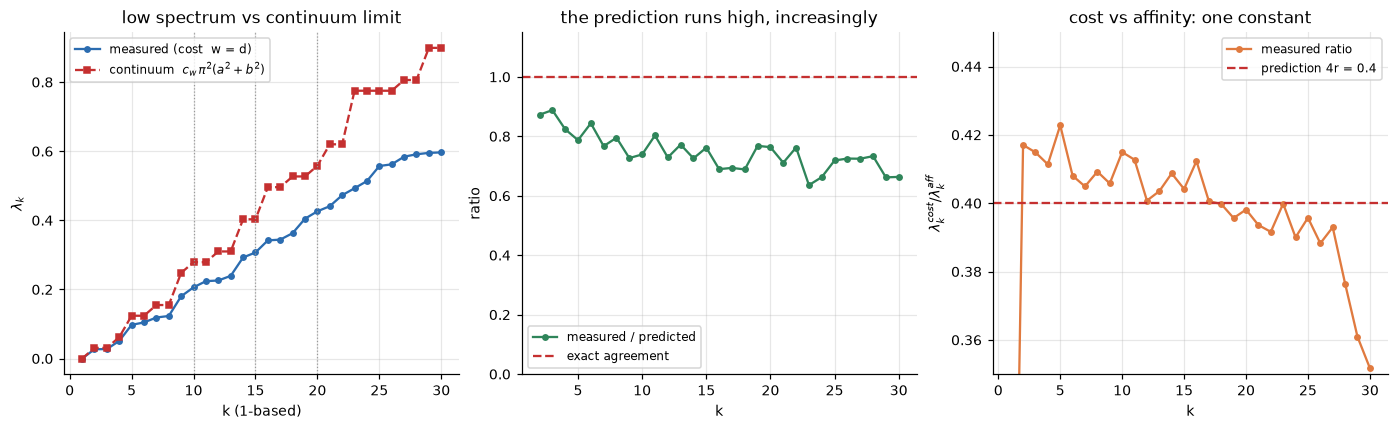

cost weights: measured vs predicted eigenvalue, with the continuum mode for each index
  k=  2  (a,b)=(0,1)   measured 0.0271   predicted 0.0310   ratio 0.873
  k=  3  (a,b)=(1,0)   measured 0.0275   predicted 0.0310   ratio 0.888
  k=  4  (a,b)=(1,1)   measured 0.0511   predicted 0.0620   ratio 0.824
  k=  5  (a,b)=(0,2)   measured 0.0976   predicted 0.1240   ratio 0.787
  k= 10  (a,b)=(0,3)   measured 0.2063   predicted 0.2791   ratio 0.739
  k= 15  (a,b)=(3,2)   measured 0.3071   predicted 0.4031   ratio 0.762
  k= 20  (a,b)=(3,3)   measured 0.4262   predicted 0.5581   ratio 0.764
  k= 25  (a,b)=(4,3)   measured 0.5573   predicted 0.7752   ratio 0.719

lambda_cost / lambda_aff over k=2..30  : mean 0.3995  (prediction 4r = 0.4)


In [7]:
# (c) continuum prediction: eigenvalues of -Laplacian on the unit square, Neumann BCs
c_cost = N * np.pi * R**5 / 10
c_aff = N * np.pi * R**4 / 40
c_unw = N * np.pi * R**4 / 8

AB_MAX = 8
neumann = sorted(((np.pi**2 * (a * a + b * b), a, b)
                  for a in range(AB_MAX) for b in range(AB_MAX)))
cont_vals = np.array([v for v, _, _ in neumann])
cont_modes = [(a, b) for _, a, b in neumann]

K_SHOW = 30
k_axis = np.arange(1, K_SHOW + 1)

fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.8))

ax = axes[0]
ax.plot(k_axis, lam_cost[:K_SHOW], "o-", color=C_LINE, ms=3.5, label="measured (cost  w = d)")
ax.plot(k_axis, c_cost * cont_vals[:K_SHOW], "s--", color=C_RED, ms=3.5,
        label=r"continuum  $c_w\,\pi^2(a^2+b^2)$")
ax.set(xlabel="k (1-based)", ylabel=r"$\lambda_k$", title="low spectrum vs continuum limit")
ax.legend(fontsize=8)
for k in (10, 15, 20):
    ax.axvline(k, color="0.6", lw=0.8, ls=":")

ax = axes[1]
# k=1 is excluded: measured and predicted are both 0 there, so the ratio is undefined.
ax.plot(k_axis[1:], lam_cost[1:K_SHOW] / (c_cost * cont_vals[1:K_SHOW]), "o-", color=C_GREEN,
        ms=3.5, label="measured / predicted")
ax.axhline(1.0, color=C_RED, ls="--", label="exact agreement")
ax.set(xlabel="k", ylabel="ratio", ylim=(0, 1.15), title="the prediction runs high, increasingly")
ax.legend(fontsize=8)

ax = axes[2]
ax.plot(k_axis, lam_cost[:K_SHOW] / lam_aff[:K_SHOW], "o-", color=C_ORANGE, ms=3.5,
        label="measured ratio")
ax.axhline(4 * R, color=C_RED, ls="--", label=f"prediction 4r = {4*R}")
ax.set(xlabel="k", ylabel=r"$\lambda_k^{cost}/\lambda_k^{aff}$", ylim=(0.35, 0.45),
       title="cost vs affinity: one constant")
ax.legend(fontsize=8)
plt.show()

print("cost weights: measured vs predicted eigenvalue, with the continuum mode for each index")
for k in [2, 3, 4, 5, 10, 15, 20, 25]:
    a, b = cont_modes[k - 1]
    print(f"  k={k:3d}  (a,b)=({a},{b})   measured {lam_cost[k-1]:.4f}   "
          f"predicted {c_cost*cont_vals[k-1]:.4f}   ratio {lam_cost[k-1]/(c_cost*cont_vals[k-1]):.3f}")
print()
print(f"lambda_cost / lambda_aff over k=2..30  : mean {np.mean(lam_cost[1:30]/lam_aff[1:30]):.4f}  "
      f"(prediction 4r = {4*R})")

The measured eigenvalues sit consistently **below** the prediction, by about 13% at $k=2$ growing
to roughly 28% by $k=25$. A gap that grows with frequency has an obvious suspect -- the second-order
Taylor expansion, which assumed the eigenfunction is smooth on the scale of $r$ and must fail for
short wavelengths. That suspect can be tested rather than assumed. For a radial kernel the *exact*
eigenvalue of the continuum integral operator on the plane wave with wavevector $\xi$ is its
Fourier symbol,

$$\lambda(\xi)=n\!\int_{\lVert z\rVert<r}\! w(\lVert z\rVert)\big(1-\cos(\xi\cdot z)\big)\,dz
=2\pi n\!\int_0^r\! w(\rho)\big(1-J_0(\lVert\xi\rVert\rho)\big)\rho\,d\rho,$$

of which $c_w\lVert\xi\rVert^2$ is just the leading term. If kernel width were the explanation, the
exact symbol would close the gap.

In [8]:
from scipy.special import j0
from scipy.integrate import quad


def exact_symbol(a, b, w_of_rho=lambda rho: rho):
    # n * integral over the disc of w(|z|) (1 - cos(xi.z)) dz, reduced to a radial integral.
    xi = np.pi * np.sqrt(a * a + b * b)                 # Neumann mode (a,b) has |xi| = pi sqrt(a^2+b^2)
    val, _ = quad(lambda rho: w_of_rho(rho) * (1 - j0(xi * rho)) * rho, 0, R)
    return N * 2 * np.pi * val


print("does the exact Fourier symbol of the kernel explain the deficit?")
print(f"{'k':>4} {'(a,b)':>7} {'measured':>10} {'quadratic':>11} {'ratio':>7} {'exact sym':>11} {'ratio':>7}")
for k in [2, 5, 10, 15, 20, 25]:
    a, b = cont_modes[k - 1]
    q = c_cost * cont_vals[k - 1]
    e = exact_symbol(a, b)
    print(f"{k:>4} {str((a,b)):>7} {lam_cost[k-1]:>10.4f} {q:>11.4f} {lam_cost[k-1]/q:>7.3f} "
          f"{e:>11.4f} {lam_cost[k-1]/e:>7.3f}")

does the exact Fourier symbol of the kernel explain the deficit?
   k   (a,b)   measured   quadratic   ratio   exact sym   ratio
   2  (0, 1)     0.0271      0.0310   0.873      0.0309   0.877
   5  (0, 2)     0.0976      0.1240   0.787      0.1219   0.801
  10  (0, 3)     0.2063      0.2791   0.739      0.2682   0.769
  15  (3, 2)     0.3071      0.4031   0.762      0.3806   0.807
  20  (3, 3)     0.4262      0.5581   0.764      0.5155   0.827
  25  (4, 3)     0.5573      0.7752   0.719      0.6942   0.803


In [9]:
def ratio_probe(n, r, seed=SEED):
    # Rebuild the whole pipeline at a different (n, r) and report measured/predicted.
    g = np.random.default_rng(seed).random((n, 2))
    pr = np.array(sorted(cKDTree(g).query_pairs(r=r)), dtype=int)
    dd = np.linalg.norm(g[pr[:, 0]] - g[pr[:, 1]], axis=1)
    Wp = np.zeros((n, n))
    Wp[pr[:, 0], pr[:, 1]] = dd
    Wp[pr[:, 1], pr[:, 0]] = dd
    lp = np.linalg.eigvalsh(np.diag(Wp.sum(1)) - Wp)
    c = n * np.pi * r**5 / 10
    return 2 * len(pr) / n, [lp[k - 1] / (c * cont_vals[k - 1]) for k in (2, 4, 10)]


print("measured / predicted, as the sample grows (same seed, same generative model)")
print(f"{'n':>6} {'r':>6} {'mean deg':>9} {'k=2':>7} {'k=4':>7} {'k=10':>7}")
for n_, r_ in [(1000, 0.10), (1000, 0.15), (2000, 0.10), (4000, 0.10), (4000, 0.05)]:
    dbar, rr = ratio_probe(n_, r_)
    print(f"{n_:>6} {r_:>6} {dbar:>9.1f} {rr[0]:>7.3f} {rr[1]:>7.3f} {rr[2]:>7.3f}")

measured / predicted, as the sample grows (same seed, same generative model)
     n      r  mean deg     k=2     k=4    k=10
  1000    0.1      29.1   0.873   0.824   0.739


  1000   0.15      61.9   0.910   0.842   0.681


  2000    0.1      58.2   0.934   0.894   0.800


  4000    0.1     115.9   0.951   0.909   0.851


  4000   0.05      29.9   0.871   0.856   0.823


### What the yardsticks say

- **Against Fiedler's bound**, $\lambda_2$ comes in at about 5% of $\frac{n}{n-1}d_{\min}$. So the
  algebraic connectivity is *not* merely a report on the worst-connected node; something global is
  suppressing it.
- **Against the rewiring null**, that something is identified: rewiring the same degree sequence
  raises $\lambda_2$ about 25-fold, with a spread across rewirings so small that the gap is not in
  question. A random graph with these degrees is an excellent expander; the geometric graph is a
  poor one, purely because its edges are local. Locality is doing the work, not the degree
  distribution. (The two kinds of null answer different questions: this one randomises the *graph*.
  A permutation null randomises a *signal* across nodes and says nothing about the operator, which
  is why it is not the right instrument here.)
- **Against the continuum**, the shape is right and the scale is about 10-30% low. The kernel's
  exact Fourier symbol recovers part of the gap -- half a point at $k=2$, about 8 points by $k=25$ --
  so kernel width is real, grows with frequency as it should, and is still not the main term.
  The $(n,r)$ sweep identifies the rest: at fixed $r$ the ratio climbs steadily
  toward 1 as $n$ grows (0.87 to 0.95 at $k=2$ going from $n=1000$ to $n=4000$), so the deficit is
  mostly **finite-sample**, the fluctuation of local point density at ~29 neighbours per node.
  Widening $r$ at fixed $n$ helps the low modes and *hurts* $k=10$, which is the kernel-width error
  reappearing: the two error sources pull in opposite directions, and $n=1000$, $r=0.1$ is a
  compromise, not a converged calculation.
- **The $4r$ ratio holds to better than 2% across the low spectrum.** Empirically, then, swapping
  the requested cost weights for a proper affinity rescales the frequency axis and very nearly
  preserves the rest. Section 6 checks whether the *eigenvectors* are equally forgiving, where the
  answer is less comfortable.

Useful habit: the continuum comparison is the strongest form of the "report spectral quantities
against a yardstick" rule, because it is a prediction with no fitted parameter. It is available
here only because the point process is known. On measured data the rewiring null usually has to
carry the load alone.

---
## 5. Before plotting $u_{10}$, $u_{15}$, $u_{20}$: are they individually well defined?

The continuum table just printed carries a warning. Neumann eigenvalues $\pi^2(a^2+b^2)$ are
frequently **degenerate**: $(3,0)$ and $(0,3)$ share $a^2+b^2=9$; $(3,2)$ and $(2,3)$ share $13$.
When two eigenvalues coincide, the individual eigenvectors are *not* determined -- only the plane
they span is. Any orthonormal pair drawn from that plane is an equally valid answer, and which one
`eigh` returns depends on rounding.

On the graph the degeneracy is broken slightly by the randomness of the sample, so we get two
distinct eigenvalues that are merely very close. That is worse than exact degeneracy, not better:
the splitting is real but tiny, so the returned pair is an essentially arbitrary rotation within
the near-plane, and a different seed rotates it differently while leaving the spectrum nearly
unchanged.

The cell below prints the relevant gaps, so this is a measurement rather than a caution. Read the
**relative gap** $(\lambda_{k+1}-\lambda_k)/\lambda_k$: where it is a few percent or less, treat
that eigenvector as a coordinate on a subspace rather than as an object in its own right.

Sign is the smaller sibling of the same problem: if $u_k$ is an eigenvector so is $-u_k$, so the
colour polarity in the next figure is arbitrary. We fix it by a stated rule -- make the
largest-magnitude entry positive -- purely so the figure is reproducible.

In [10]:
print("eigenvalue spacing around the requested modes (cost weights)")
print(f"{'k':>4} {'lambda_k':>12} {'rel gap to k+1':>16}   continuum (a,b)")
for k in range(8, 23):
    gap = (lam_cost[k] - lam_cost[k - 1]) / lam_cost[k - 1]
    a, b = cont_modes[k - 1]
    flag = "  <-- near-degenerate pair" if gap < 0.03 else ""
    star = " *" if k in (10, 15, 20) else "  "
    print(f"{k:>4}{star}{lam_cost[k-1]:>12.5f} {gap:>16.4f}   ({a},{b}){flag}")

eigenvalue spacing around the requested modes (cost weights)
   k     lambda_k   rel gap to k+1   continuum (a,b)
   8       0.12332           0.4623   (2,1)
   9       0.18032           0.1439   (2,2)
  10 *     0.20627           0.0865   (0,3)
  11       0.22411           0.0086   (3,0)  <-- near-degenerate pair
  12       0.22604           0.0594   (1,3)
  13       0.23946           0.2220   (3,1)
  14       0.29263           0.0495   (2,3)
  15 *     0.30711           0.1141   (3,2)
  16       0.34214           0.0061   (0,4)  <-- near-degenerate pair
  17       0.34423           0.0546   (4,0)
  18       0.36301           0.1153   (1,4)
  19       0.40488           0.0527   (4,1)
  20 *     0.42622           0.0349   (3,3)
  21       0.44108           0.0720   (2,4)
  22       0.47283           0.0425   (4,2)


### Do these eigenvectors actually look like their continuum partners?

Section 4 matched *eigenvalues* to continuum modes. That match is an ordering argument and it says
nothing about the eigenvectors, so it has to be tested separately. The test: express each graph
eigenvector in the (near-orthogonal) system of sampled cosine modes
$\phi_{ab}(p)=\cos(a\pi x)\cos(b\pi y)$ and read off where its energy went. A clean discretisation
would put essentially all of $u_k$ on its predicted $(a,b)$.

In [11]:
M_CONT = 30
B = np.column_stack([np.cos(a * np.pi * coords[:, 0]) * np.cos(b * np.pi * coords[:, 1])
                     for a, b in cont_modes[:M_CONT]])
B = B / np.linalg.norm(B, axis=0)          # unit columns; nearly (not exactly) orthogonal
Qc, _ = np.linalg.qr(B)                    # orthonormal basis for the same span

print("where each graph eigenvector's energy sits among the sampled continuum modes")
print(f"{'k':>4} {'predicted':>10} {'in span':>9}   top matches (energy fraction)")
for k in (2, 3, 4, 9, 10, 15, 20):
    u = U_cost[:, k - 1]
    ov = (B.T @ u) ** 2
    in_span = float(np.sum((Qc.T @ u) ** 2))
    top = np.argsort(ov)[::-1][:3]
    s = "   ".join(f"{cont_modes[j]}: {ov[j]:.2f}" for j in top)
    print(f"{k:>4} {str(cont_modes[k-1]):>10} {in_span:>9.2f}   {s}")

where each graph eigenvector's energy sits among the sampled continuum modes
   k  predicted   in span   top matches (energy fraction)
   2     (0, 1)      1.00   (0, 1): 0.94   (1, 0): 0.05   (4, 2): 0.01
   3     (1, 0)      1.00   (1, 0): 0.94   (0, 1): 0.04   (1, 1): 0.02
   4     (1, 1)      0.99   (1, 1): 0.95   (0, 1): 0.01   (4, 1): 0.01
   9     (2, 2)      0.96   (0, 3): 0.31   (1, 3): 0.23   (3, 0): 0.14
  10     (0, 3)      0.98   (3, 0): 0.46   (2, 2): 0.17   (0, 3): 0.16
  15     (3, 2)      0.94   (2, 3): 0.27   (4, 0): 0.25   (3, 2): 0.22
  20     (3, 3)      0.87   (1, 4): 0.18   (0, 4): 0.17   (4, 2): 0.14


In [12]:
# Localisation. The inverse participation ratio 1/(n * sum u_i^4) is 1 for a perfectly spread
# unit vector and ~1/n for one concentrated on a single node.
def part_ratio(u):
    return 1.0 / (N * np.sum(u ** 4))


print(f"{'k':>5} {'lambda_k':>10} {'participation':>14}   mean degree of the 5% largest-|u| nodes")
for k in (2, 3, 10, 15, 20, 500, 1000):
    u = U_cost[:, k - 1]
    top = np.argsort(np.abs(u))[::-1][:N // 20]
    print(f"{k:>5} {lam_cost[k-1]:>10.4f} {part_ratio(u):>14.3f}   "
          f"{deg_unw[top].mean():>6.1f}   (all nodes: {deg_unw.mean():.1f})")

on_boundary = np.min(np.minimum(coords, 1 - coords), axis=1) < R
print(f"\nnodes within r of the square's edge: {on_boundary.sum()} of {N} ({on_boundary.mean():.0%})")
for k in (2, 10, 15, 20):
    u = U_cost[:, k - 1]
    share = float(np.sum(u[on_boundary] ** 2))
    print(f"  u_{k:<3d} share of its energy on those nodes: {share:.2f}")

    k   lambda_k  participation   mean degree of the 5% largest-|u| nodes
    2     0.0271          0.587     22.6   (all nodes: 29.1)
    3     0.0275          0.589     23.3   (all nodes: 29.1)
   10     0.2063          0.309     21.6   (all nodes: 29.1)
   15     0.3071          0.288     18.9   (all nodes: 29.1)
   20     0.4262          0.209     21.5   (all nodes: 29.1)
  500     1.9716          0.045     30.2   (all nodes: 29.1)
 1000     3.3621          0.022     36.8   (all nodes: 29.1)

nodes within r of the square's edge: 358 of 1000 (36%)
  u_2   share of its energy on those nodes: 0.54
  u_10  share of its energy on those nodes: 0.56
  u_15  share of its energy on those nodes: 0.59
  u_20  share of its energy on those nodes: 0.48


That is the first uncomfortable result, and it is worth stating plainly rather than burying.

**Only the lowest modes are clean.** $u_2$, $u_3$ and $u_4$ put ~95% of their energy on exactly the
continuum mode the eigenvalue ordering predicts. By $k=10$ the predicted mode is no longer even the
largest component, and $u_{20}$ is spread across half a dozen continuum modes with no single one
above ~0.2. The eigenvalues follow the continuum ordering; the eigenvectors, at $n=1000$, do not
resolve into individual continuum modes at these indices. Levels that are nearly degenerate mix
under any perturbation, and the sampling noise measured in Section 4 is exactly such a
perturbation.

**Amplitude concentrates as you climb the spectrum.** The participation ratio falls from about 0.59
at $u_2,u_3$ to 0.21-0.31 at the requested indices, and to a few percent at the top of the
spectrum: a mid-band mode spreads its energy over roughly half as many nodes as the lowest modes
do. The extreme entries sit preferentially on low-degree nodes, which makes sense -- a low-degree
node is cheap to make large, having fewer edges to disagree across.

What is *not* distinctive is the boundary, and it is worth recording the negative result since it
is the tempting explanation. Every mode here, $u_2$ as much as $u_{20}$, puts around half its
energy on the 36% of nodes lying within $r$ of the rim, simply because cosine modes are extremal at
the edges. So read the concentration as a frequency effect plus a degree effect, not as a boundary
artefact. The practical consequence is the same either way: a handful of nodes own the top of the
$|u_k|$ range, which is why the next figure needs a robust colour scale to show anything at all.

Neither observation invalidates the spectrum. Both mean that *individual* mid-band eigenvectors are
weak objects here -- which is precisely the material the requested clustering is built from.

---
## 6. The requested eigenvectors, as node colours

Each panel below colours all 1000 nodes by one entry of one eigenvector. There is no smoothing and
no interpolation: what looks like a continuous field is 1000 dots whose values happen to vary
slowly in space, and *that* is the content of the picture.

Nothing in the Laplacian knows where the points are. The coordinates entered only through which
pairs fell within $r$ and what weight each edge got; having done that, the eigenvector is a
property of the matrix alone. Redrawing the same graph with the nodes moved would scramble these
pictures while leaving the spectrum identical.

Because of the concentration measured above, the colour limits are set at the 98th percentile of
$|u_k|$ rather than at the maximum; each panel title reports how many nodes are clipped. At full
range the figure is nearly blank, a handful of extreme nodes owning the whole scale. This is a
presentation choice, stated so you can undo it.

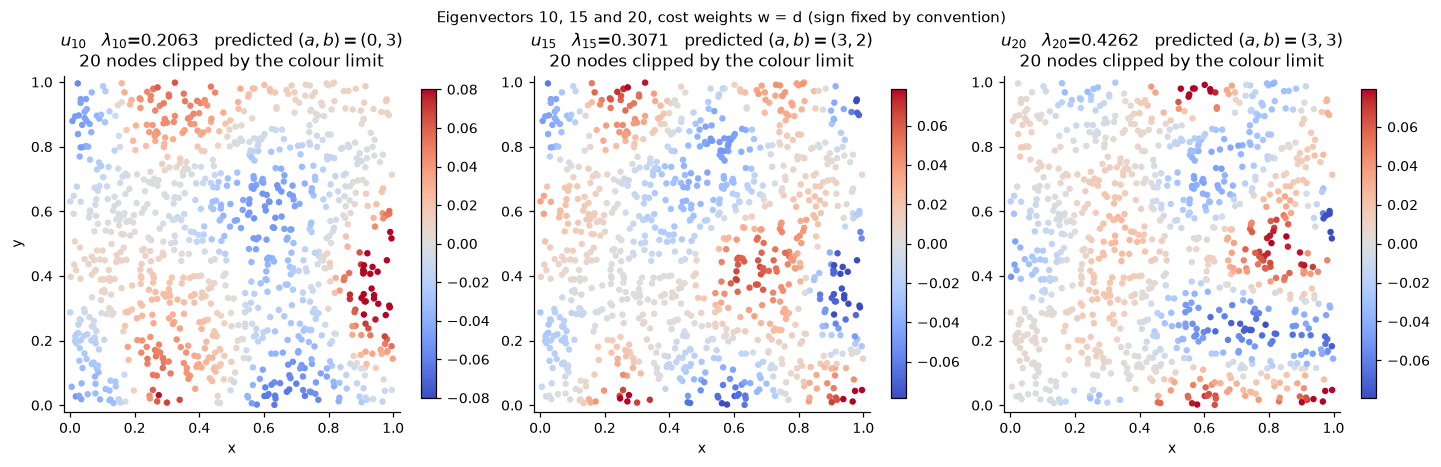

Dirichlet energy check, both indexing conventions, against lambda_k:
  k= 10   edge sum 0.206271   (1/2) ordered-pair sum 0.206271   u^T L u 0.206271   lambda_k 0.206271
  k= 15   edge sum 0.307115   (1/2) ordered-pair sum 0.307115   u^T L u 0.307115   lambda_k 0.307115
  k= 20   edge sum 0.426217   (1/2) ordered-pair sum 0.426217   u^T L u 0.426217   lambda_k 0.426217


In [13]:
SHOW_K = (10, 15, 20)


def fix_sign(v):
    # Eigenvectors are defined up to sign; pin it so the figures are reproducible.
    return v if v[np.argmax(np.abs(v))] > 0 else -v


def eigen_panels(U, lam, title):
    fig, axes = plt.subplots(1, 3, figsize=(13.0, 4.1))
    for ax, k in zip(axes, SHOW_K):
        u = fix_sign(U[:, k - 1])
        vmax = np.quantile(np.abs(u), 0.98)
        n_clip = int(np.sum(np.abs(u) > vmax))
        a, b = cont_modes[k - 1]
        sc = ax.scatter(coords[:, 0], coords[:, 1], c=u, cmap="coolwarm", vmin=-vmax, vmax=vmax,
                        s=18, edgecolors="none")
        ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02), aspect="equal", xlabel="x",
               title=f"$u_{{{k}}}$   $\\lambda_{{{k}}}$={lam[k-1]:.4f}   "
                     f"predicted $(a,b)=({a},{b})$\n{n_clip} nodes clipped by the colour limit")
        ax.grid(False)
        fig.colorbar(sc, ax=ax, fraction=0.046)
    axes[0].set_ylabel("y")
    fig.suptitle(title, fontsize=10)
    plt.show()


eigen_panels(U_cost, lam_cost, "Eigenvectors 10, 15 and 20, cost weights w = d (sign fixed by convention)")

print("Dirichlet energy check, both indexing conventions, against lambda_k:")
for k in SHOW_K:
    u = U_cost[:, k - 1]
    edge_sum = float(np.sum(w_cost * (u[pairs[:, 0]] - u[pairs[:, 1]]) ** 2))
    pair_sum = 0.5 * float(np.sum(W_cost * (u[:, None] - u[None, :]) ** 2))
    print(f"  k={k:3d}   edge sum {edge_sum:.6f}   (1/2) ordered-pair sum {pair_sum:.6f}   "
          f"u^T L u {float(u @ L_cost @ u):.6f}   lambda_k {lam_cost[k-1]:.6f}")

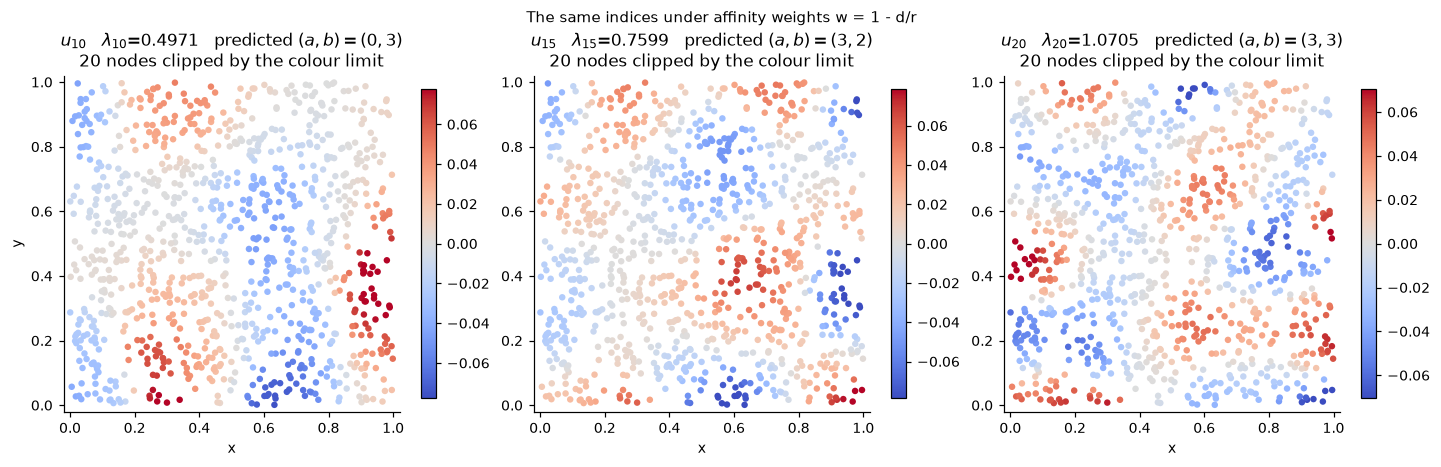

cost weights vs affinity weights
  |correlation| of matched single eigenvectors:
    u10: 0.969   u15: 0.927   u20: 0.807
  principal angles, span(u10,u15,u20)  : [14.1 21.7 36.5] deg
  principal angles, span(u2,u3,u4)     : [1.8 1.9 2.8] deg


In [14]:
# The same three indices computed from the affinity weights.
eigen_panels(U_aff, lam_aff, "The same indices under affinity weights w = 1 - d/r")

# Individual eigenvectors need not match across operators (near-degenerate levels rotate),
# but a subspace can match even when its basis vectors do not. Principal angles test that.
def principal_angles(A, Bm):
    sv = np.linalg.svd(A.T @ Bm, compute_uv=False)
    return np.degrees(np.arccos(np.clip(sv, -1, 1)))


print("cost weights vs affinity weights")
print("  |correlation| of matched single eigenvectors:")
print("    " + "   ".join(f"u{k}: {abs(np.corrcoef(U_cost[:, k-1], U_aff[:, k-1])[0,1]):.3f}"
                          for k in SHOW_K))
ang_mid = principal_angles(U_cost[:, [k - 1 for k in SHOW_K]], U_aff[:, [k - 1 for k in SHOW_K]])
ang_low = principal_angles(U_cost[:, 1:4], U_aff[:, 1:4])
print(f"  principal angles, span(u10,u15,u20)  : {np.array2string(ang_mid, precision=1)} deg")
print(f"  principal angles, span(u2,u3,u4)     : {np.array2string(ang_low, precision=1)} deg")

Read the two rows of panels together with the numbers under them.

The eigenvalues obey the $4r$ scaling almost exactly, and at the bottom of the spectrum the two
operators agree on the basis too: $\mathrm{span}(u_2,u_3,u_4)$ is nearly the same plane under both
weightings, with principal angles of a few degrees. At the requested indices the agreement is
looser -- matched eigenvectors correlate around 0.8-0.97 and the two 3-D spans differ by 14-37
degrees. The requested modes are *similar* under the two weight definitions, not interchangeable.

So the honest summary of the cost-vs-affinity question on this graph: **the frequency axis rescales
by a known constant, the low modes are robust, and the mid-band modes are only approximately
preserved.** The sensitivity that does exist is concentrated exactly where Section 5 said the
eigenvectors were weakly determined. Comparing single coefficients across two different operators
would be the wrong test; comparing subspaces is the right one, and even that shows visible drift
here.

---
## 7. Clustering on modes 10, 15 and 20 -- and what it is worth

The request: build node clusters from these three eigenvectors. The construction is standard in
form. Embed each node in $\mathbb{R}^3$ by its three eigenvector entries,

$$y_i=\big(u_{10,i},\;u_{15,i},\;u_{20,i}\big)\in\mathbb{R}^3,$$

and run k-means. What is **not** standard is the choice of modes. Spectral clustering as usually
stated (von Luxburg 2007, [R1]) embeds with $u_2,\dots,u_K$ -- the *lowest* nonconstant modes --
because those are the vectors of smallest Dirichlet energy, so a partition that respects them cuts
few edges. Modes 10, 15 and 20 carry 8-16 times the energy of $u_2$ here. A partition aligned with
them cuts many edges by construction, so if it is to be useful it must be useful for some reason
other than cut size.

We fix $K=8$ -- natural for three vectors, since the sign pattern of three numbers has $2^3$ cells
-- and compare four partitions:

| label | how it is built | what it represents |
|---|---|---|
| `mid-band` | k-means on $(u_{10},u_{15},u_{20})$ | the requested method |
| `sign` | sign pattern of the same three vectors | the same idea with nothing fitted |
| `low-band` | k-means on $(u_2,\dots,u_8)$ | textbook spectral clustering |
| `coords` | k-means on $(x,y)$ | the non-spectral alternative a practitioner reaches for first |

scored on the quantity spectral clustering exists to minimise, the normalised cut

$$\mathrm{Ncut}(C_1,\dots,C_K)=\sum_{c}\frac{\mathrm{cut}(C_c,\overline{C_c})}{\mathrm{vol}(C_c)},$$

with $\mathrm{cut}$ and $\mathrm{vol}$ computed from the *cost* weights $W_{ij}=d_{ij}$ that define
the graph. Lower is better and $K=8$ is the worst attainable value. Two descriptive statistics come
along: the mean in-plane radius of a cluster, and the number of connected pieces each cluster
breaks into on the graph -- a partition into 8 groups that yields far more than 8 pieces is not
describing regions.

In [15]:
K = 8


def kmeans_labels(X, k=K, seed=SEED):
    return KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(X)


Y_mid = U_cost[:, [k - 1 for k in SHOW_K]]                 # u10, u15, u20
Y_low = U_cost[:, 1:8]                                     # u2 ... u8
lab_mid = kmeans_labels(Y_mid)
lab_low = kmeans_labels(Y_low)
lab_xy = kmeans_labels(coords)
lab_sign = (4 * (Y_mid[:, 0] > 0) + 2 * (Y_mid[:, 1] > 0) + (Y_mid[:, 2] > 0)).astype(int)

PARTS = [("mid-band  u10,u15,u20", lab_mid), ("sign pattern of the same", lab_sign),
         ("low-band  u2..u8", lab_low), ("coordinates x,y", lab_xy)]


def ncut(W, labels):
    total = 0.0
    for c in np.unique(labels):
        m = labels == c
        vol = W[m].sum()
        if vol == 0:
            continue
        total += W[np.ix_(m, ~m)].sum() / vol
    return total


def cluster_stats(labels):
    sizes = np.bincount(labels, minlength=labels.max() + 1)
    sizes = sizes[sizes > 0]
    rad, pieces = [], 0
    for c in np.unique(labels):
        pts = coords[labels == c]
        rad.append(np.linalg.norm(pts - pts.mean(0), axis=1).mean())
        pieces += nx.number_connected_components(G.subgraph(np.flatnonzero(labels == c)))
    return len(sizes), sizes.min(), sizes.max(), np.mean(rad), pieces


print(f"{'partition':28s} {'K':>3} {'min':>5} {'max':>5} {'Ncut':>8} {'radius':>8} {'pieces':>8}")
for name, lab in PARTS:
    k_eff, lo, hi, rad, pieces = cluster_stats(lab)
    print(f"{name:28s} {k_eff:>3} {lo:>5} {hi:>5} {ncut(W_cost, lab):>8.3f} {rad:>8.4f} {pieces:>8}")
print(f"{'(worst possible Ncut)':28s} {K:>3} {'':>5} {'':>5} {float(K):>8.3f}")

partition                      K   min   max     Ncut   radius   pieces


mid-band  u10,u15,u20          8    36   280    2.856   0.3204       28
sign pattern of the same       8    75   166    3.788   0.3387       40
low-band  u2..u8               8    46   187    1.178   0.1306        8
coordinates x,y                8   107   154    1.348   0.1339        8
(worst possible Ncut)          8                8.000


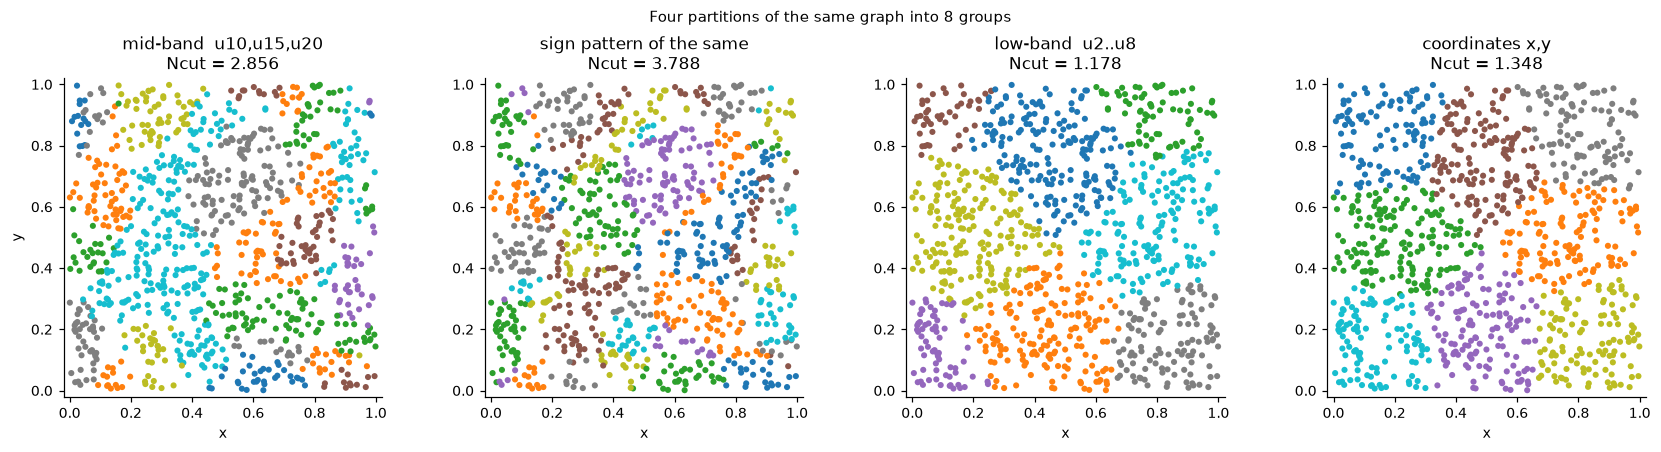

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.0))
for ax, (name, lab) in zip(axes, PARTS):
    ax.scatter(coords[:, 0], coords[:, 1], c=lab, cmap="tab10", s=16, edgecolors="none")
    ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02), aspect="equal", xlabel="x",
           title=f"{name}\nNcut = {ncut(W_cost, lab):.3f}")
    ax.grid(False)
axes[0].set_ylabel("y")
fig.suptitle("Four partitions of the same graph into 8 groups", fontsize=10)
plt.show()

In [17]:
# Agreement between partitions. ARI is 0 for chance agreement, 1 for identity.
print("adjusted Rand index between partitions")
names = [n for n, _ in PARTS]
labs = [l for _, l in PARTS]
print(f"{'':28s}" + "".join(f"{n[:12]:>14s}" for n in names))
for i, n in enumerate(names):
    row = "".join(f"{adjusted_rand_score(labs[i], labs[j]):>14.3f}" for j in range(len(labs)))
    print(f"{n:28s}{row}")

# Does the weight definition change the answer?
lab_mid_aff = kmeans_labels(U_aff[:, [k - 1 for k in SHOW_K]])
lab_low_aff = kmeans_labels(U_aff[:, 1:8])
print()
print(f"mid-band partition, cost vs affinity weights : ARI = {adjusted_rand_score(lab_mid, lab_mid_aff):.3f}")
print(f"low-band partition, cost vs affinity weights : ARI = {adjusted_rand_score(lab_low, lab_low_aff):.3f}")

# Stability under a different k-means initialisation (the graph and basis are unchanged).
print()
print("stability across k-means seeds (ARI vs seed 11):")
for name, Y, base in [("mid-band", Y_mid, lab_mid), ("low-band", Y_low, lab_low),
                      ("coords", coords, lab_xy)]:
    s = "  ".join(f"seed {t}: {adjusted_rand_score(base, kmeans_labels(Y, seed=t)):.3f}"
                  for t in (12, 13, 14))
    print(f"  {name:10s} {s}")

adjusted Rand index between partitions
                              mid-band  u1  sign pattern  low-band  u2  coordinates 
mid-band  u10,u15,u20                1.000         0.266         0.168         0.151
sign pattern of the same             0.266         1.000         0.111         0.102
low-band  u2..u8                     0.168         0.111         1.000         0.720
coordinates x,y                      0.151         0.102         0.720         1.000

mid-band partition, cost vs affinity weights : ARI = 0.343
low-band partition, cost vs affinity weights : ARI = 0.948

stability across k-means seeds (ARI vs seed 11):


  mid-band   seed 12: 0.690  seed 13: 0.925  seed 14: 0.698
  low-band   seed 12: 1.000  seed 13: 0.998  seed 14: 1.000


  coords     seed 12: 1.000  seed 13: 0.974  seed 14: 0.988


### Reading the table honestly

**1. The requested partition is an interference pattern, not a set of regions.** Its eight groups
have a mean in-plane radius more than twice that of the coordinate clusters, and they shatter into
far more connected pieces than there are clusters. That is what clustering on oscillating modes
produces: a cell is the set of nodes where three sign patterns agree, and since each mode has
several nodal stripes, that set recurs across the square in disconnected patches. The picture
confirms it -- the mid-band and sign panels are interleaved, the low-band and coordinate panels are
contiguous territories.

**2. On the criterion spectral clustering is named for, plain k-means on $(x,y)$ beats it.** The
coordinate baseline never builds a graph, never forms a Laplacian, and runs in milliseconds, and it
reaches a normalised cut less than half the requested method's. This is the instructive outcome and
it is not an accident: on a radius graph, edges exist exactly where points are close, so a compact
region in the plane is automatically a low-cut region and coordinate k-means is already optimising
a good proxy for the cut.

**3. The mode choice failed, not the spectral idea -- but its margin is thin.** `low-band`, the
same pipeline with $u_2,\dots,u_8$, gives the lowest Ncut of the four. It beats the coordinate
baseline by roughly 13%, and it agrees with it substantially (ARI about 0.72). So the correct
reading is not *spectral clustering wins* but *spectral clustering recovers approximately the
geometric partition and trims the cut a little*. On a uniform point cloud there is no community
structure for it to find that geometry does not already supply. The place to expect a real gap is
a point cloud with density structure, where compactness and low cut stop coinciding.

**4. The requested partition is also the least stable.** It moves under a change of k-means seed
and moves more under the cost/affinity swap, while the low-band partition is nearly invariant to
both. Section 5 predicted this: two of the three chosen vectors sit in near-degenerate levels, so
the embedding they define is determined only up to a rotation, and clustering is not invariant to
rotating its input. A partition that changes when you re-run it with a different seed is not a
finding about the graph.

**What this does not say.** Mid-band modes are not useless -- they are a legitimate frequency-band
description, and filtering or characterising a signal with them is a normal and useful thing to do
(Lesson 2). The narrow claim here is that *k-means on a handful of individually ill-determined
mid-band eigenvectors* does not produce meaningful node groups on this graph, and that the
resulting tiles should not be described as communities.

---
## 8. Conclusion

**What was built.** A 1000-node random geometric graph on the unit square, $r=0.1$, with
$W_{ij}=d_{ij}$ exactly as specified; its combinatorial Laplacian spectrum computed exactly and
verified; eigenvectors 10, 15 and 20 displayed; and four 8-way partitions compared, including the
requested one.

**What the analysis supports.**

- The spectrum of this graph is a discretisation of $-\Delta$ on the square with Neumann boundary
  conditions. The measured low eigenvalues follow $c_w\pi^2(a^2+b^2)$ in shape and ordering, with
  $c_w$ computed from the weight kernel and nothing fitted, at a scale 10-30% low. An $(n,r)$ sweep
  attributes most of that deficit to finite sampling -- the ratio climbs toward 1 as $n$ grows --
  and the kernel's exact Fourier symbol accounts for a few points more.
- Weighting by distance rather than by an affinity rescales the frequency axis by $4r$, to better
  than 2%, and leaves the low eigenvectors essentially intact. On this construction the
  cost/affinity distinction is close to a scale factor, because the radius cutoff has already
  confined every edge to one length scale. That does not transfer to graphs whose edge costs span
  decades, where the distinction inverts the geometry.
- Locality, not the degree sequence, is what makes this graph a poor expander: a degree-preserving
  rewiring raises $\lambda_2$ about 25-fold.

**What it does not support.**

- The mid-band eigenvectors are **not** clean continuum modes at $n=1000$. Measured against sampled
  cosine modes, $u_2$-$u_4$ are ~95% pure while $u_{10}$, $u_{15}$ and $u_{20}$ are mixtures across
  several nearby modes, with their amplitude increasingly concentrated on a small set of
  low-degree nodes.
  Any statement about one of them individually inherits that ambiguity; statements about the
  subspace they span do not.
- The mid-band partition is not a community structure, and there is none in a uniform random
  geometric graph to find. Its groups are disconnected interference cells, its normalised cut is
  more than double the coordinate baseline's, and it moves under a change of random seed.
- Nothing here is evidence of a physical field, a diffusion process or any dynamics. These are
  patterns that minimise Dirichlet energy subject to orthogonality, and they would be identical for
  any graph with this connectivity, whatever the nodes represented.

**Limitations.**

- One realisation, one seed. The qualitative results -- continuum ordering, the expander gap, the
  interference-cell behaviour -- are properties of the model and reproduce across seeds. Individual
  mid-band eigenvectors do not.
- $n=1000$ at $r=0.1$ is a compromise between two competing errors (sampling noise, which wants
  large $n$ and wide $r$; kernel-width bias, which wants small $r$ relative to the wavelength). It
  is not a converged calculation, and the convergence table is there so the reader can see the size
  of what is being tolerated.
- $K=8$ was chosen from the structure of the method ($2^3$ sign cells), not from the data. There is
  no natural cluster count to recover here, so no $K$ would be *correct* -- itself worth noticing
  before running a clustering algorithm on any dataset.

**Where to take it next.** Replace the uniform density with a clustered one -- a mixture of
Gaussians, say -- and repeat Section 7. With real density structure the low-band partition should
recover it while coordinate k-means starts to fail, since compactness and low cut stop coinciding.
That contrast is exactly what the uniform case, by construction, cannot show.

**References.**

- **[R1]** von Luxburg (2007), [A Tutorial on Spectral Clustering](https://arxiv.org/abs/0711.0189)
  -- the $u_2,\dots,u_K$ embedding, Ncut, and why the bottom of the spectrum is the right end.
- **[R2]** Shuman et al. (2013), [The Emerging Field of Signal Processing on Graphs](https://arxiv.org/abs/1211.0053)
  -- graph frequency, the GFT and filtering.
- Penrose (2003), *Random Geometric Graphs*, Oxford University Press -- degree, connectivity
  thresholds and limit theory for $G(n,r)$.
- Belkin and Niyogi (2008), [Towards a theoretical foundation for Laplacian-based manifold methods](https://doi.org/10.1016/j.jcss.2007.08.006)
  -- convergence of the graph Laplacian to the Laplace-Beltrami operator, the result Section 4's
  continuum yardstick leans on.
- Fiedler (1973), *Algebraic connectivity of graphs*, Czechoslovak Math. J. 23(2), 298-305 -- the
  $\lambda_2\le\frac{n}{n-1}d_{\min}$ bound.

**How to run it.** Python 3.12 with numpy, scipy, networkx, matplotlib and scikit-learn; versions
printed by the first cell. Run top to bottom from a fresh kernel. No data is downloaded -- the point
cloud is generated from `SEED = 11` -- and the notebook executes in about a minute, most of it in
the $(n,r)$ convergence sweep in Section 4.